## 四元固溶体相のDOS

全電子第一原理計算を行った四元固溶体相のDOSを示します。

***説明変数***

- Z1, Z2, Z3, Z3: 4元合金の元素

もしくは
- elm1, elm2, elm3, elm4: 4元合金の元素

***目的変数***

- log10_dos*:  DOS(E)

***meta data***

- semicore: セミコア順位を与える元素名

説明変数、目的変数の解釈はこれだけではありません。

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

In [2]:
def get_data():
    filename = "../data/dos/hea4_dos.csv"
    df = pd.read_csv(filename, index_col=None)
    meta_names = ['Z1', 'Z2', 'Z3', 'Z4',
    'elm1', 'elm2', 'elm3', 'elm4', 'elements',  ]
    descriptor_names = []
    for i in range(100):
        descriptor_names.append("log10_dos{}".format(i+1))
    target_name = 'semicore'

    descriptor_names = descriptor_names[0:100]
    return df, descriptor_names, meta_names, target_name

g_df, g_logdos_names, g_meta_names, g_target_name = get_data()
g_descriptor_names = g_logdos_names
g_df

,Z1,Z2,Z3,Z4,log10_dos1,log10_dos2,log10_dos3,log10_dos4,log10_dos5,log10_dos6,...,log10_dos97,log10_dos98,log10_dos99,log10_dos100,elm1,elm2,elm3,elm4,elements,semicore
0,23,25,50,78,-3.113509,-3.045757,-3.000000,-2.974694,-2.958607,-2.954677,...,0.009026,0.044775,0.076284,0.104473,V,Mn,Sn,Pt,",V,Mn,Sn,Pt,",Sn
1,25,26,48,50,-3.040959,-2.974694,-2.935542,-2.913640,-2.906578,-2.906578,...,0.105462,0.195637,0.323516,0.569436,Mn,Fe,Cd,Sn,",Mn,Fe,Cd,Sn,",Sn
2,22,25,28,50,-2.669586,-2.673664,-2.675718,-2.677781,-2.681937,-2.690370,...,-0.064045,-0.022167,0.013562,0.044724,Ti,Mn,Ni,Sn,",Ti,Mn,Ni,Sn,",Sn
3,13,28,50,79,-3.130768,-3.055517,-3.000000,-2.966576,-2.950782,-2.943095,...,0.084891,0.118840,0.149053,0.176386,Al,Ni,Sn,Au,",Al,Ni,Sn,Au,",Sn
4,25,29,44,50,-3.154902,-3.045757,-2.974694,-2.928118,-2.896196,-2.882729,...,0.007411,0.037167,0.063836,0.087955,Mn,Cu,Ru,Sn,",Mn,Cu,Ru,Sn,",Sn
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,24,42,77,79,-3.221849,-3.251812,-3.283997,-3.301030,-3.337242,-3.356547,...,-2.769551,-2.725842,-2.677781,-2.612610,Cr,Mo,Ir,Au,",Cr,Mo,Ir,Au,",Mo
596,25,42,78,79,-3.214670,-3.244125,-3.267606,-3.283997,-3.309804,-3.327902,...,-2.769551,-2.730487,-2.686133,-2.632644,Mn,Mo,Pt,Au,",Mn,Mo,Pt,Au,",Mo
597,29,30,42,77,-3.301030,-3.420216,-3.552842,-3.744727,-3.920819,-4.221849,...,-2.661544,-2.616185,-2.571865,-2.519993,Cu,Zn,Mo,Ir,",Cu,Zn,Mo,Ir,",Mo
598,22,24,42,43,-2.489455,-2.559091,-2.619789,-2.673664,-2.721246,-2.764472,...,-3.075721,-3.065502,-3.045757,-3.026872,Ti,Cr,Mo,Tc,",Ti,Cr,Mo,Tc,",Mo


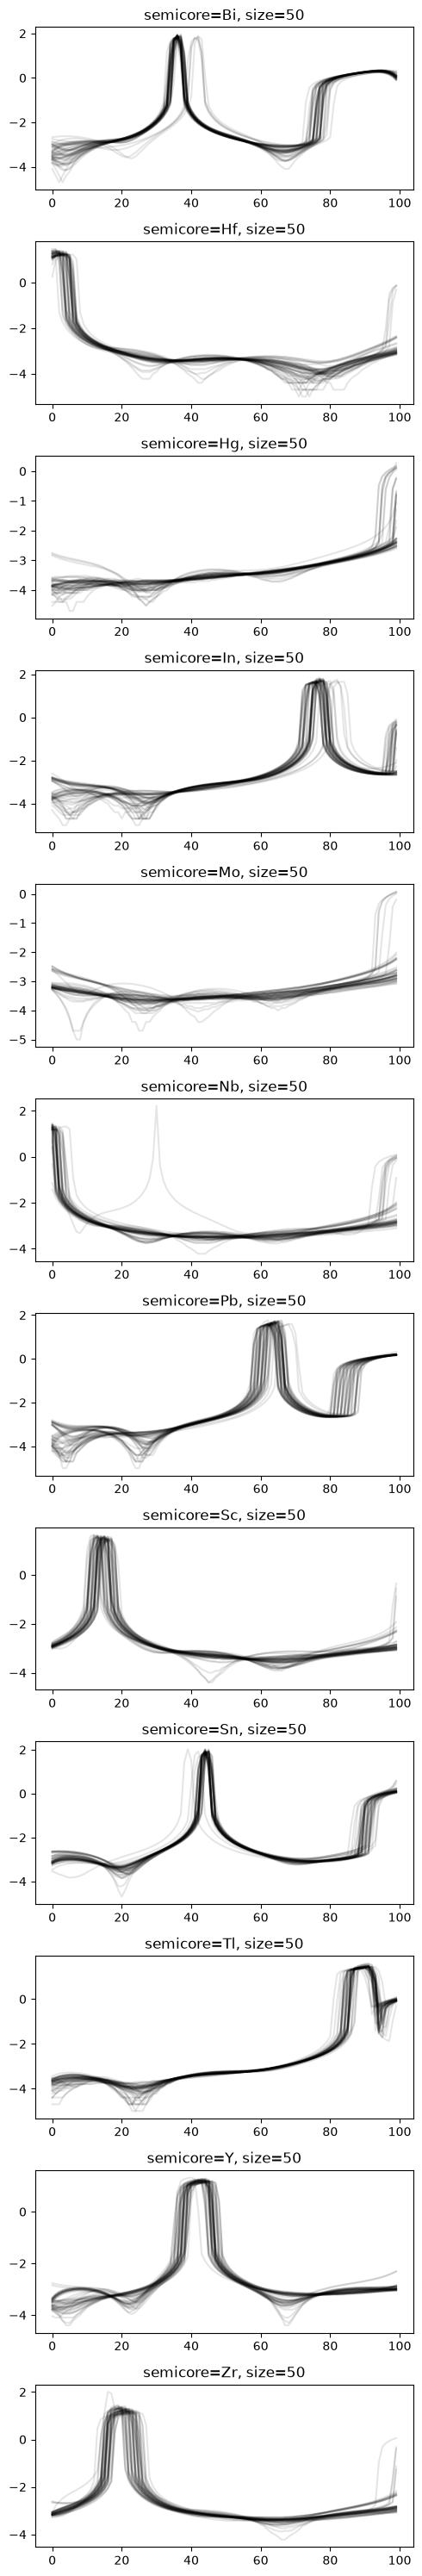

In [3]:
def plot_dos_cluster(df, cluster_name,  logdos_names, ):
    """
    plot DOS of clusters
    
    Args:
        df (pd.DataFrame): データ.
        cluster_name ([str]): 説明変数名.
        smearedlogdos_names ([str]): 次元圧縮した説明変数名.
        logdos_names ([str]): 説明変数名.
    """
    
    uniq_clusters = np.unique(df[cluster_name].values)
    n_clusters = uniq_clusters.shape[0]
    fig, axes = plt.subplots(n_clusters,1, figsize=(5,2.5*n_clusters))

    for _i, _name in enumerate(uniq_clusters):
        df_select = df[df[cluster_name]==_name]
        if df_select.shape[0]>0:
            ax = axes[_i]
            y = df_select[logdos_names].values.T
            x = np.array(list(range(y.shape[0])))
            ax.plot(x,y, alpha=0.1, c="black")
            ax.set_title("semicore={}, size={}".format(_name, y.shape[1]))

    fig.tight_layout()
        
plot_dos_cluster(g_df, "semicore",   g_logdos_names, )

失敗した結果も含まれます。